# Agentic-checkout tracker: Muse sources vs Prime Omega (2822)

**Question.** How does the agentic (Stripe Link agent) trend change with the card source?

| | Source | Agentic match on | Denominator (per million) |
|---|---|---|---|
| **(a) Muse app** | Yodlee feeds 3/4/6, card + bank (`SRS_MCP.META.MUSE_CARD_TXNS`, `MUSE_PANEL_TOTALS`) | Yodlee `DESCRIPTION` | Distinct transactions in the same feeds |
| **(b) Josh's view** | `EARNEST.COMMON.CE_PRIME_OMEGA_PANEL_TXNS` (Omega, CS 2019/2022 panels, ex affected accounts) | `MERCHDESC` | Distinct transactions in the same panels (unweighted), and the CS 2022 weighted rate |
| **(c) TRANS_V1_0 ⨝ MID_V1_0** | All of Prime Omega, ex affected accounts | `MID_V1_0.MERCHDESC` | All Omega transactions |

All three use the app's rule (`agentic_sql`: `LINKAGNT*`, or `LINK*` anchored on `www.link.co` / `south san fra`). The comparison covers **September 2026**: the pre-launch week, the Muse launch (8 Sep) and the descriptor rename (23 Sep). Data is pulled from 25 Aug so the trailing 7-day rate is complete from 1 Sep; September is well inside every source's reporting lag (the Muse tables were last loaded 2026-10-13). Rates are ratios of trailing 7-day sums, as in the app.

**Method notes**
- (b) agentic counts are read from the view itself, deduplicated to one row per `TRANSID` (the view repeats a transaction per matching ticker). The view is too slow to scan for every transaction, so its denominator is rebuilt from the same base tables and filters (`TRANS_V1_0` inner-joined to the two panels, ex `AFFECTED_ACCOUNTS_092026`). Every other join in the view is a LEFT JOIN and cannot change which transactions it holds. Cell 4 checks that the agentic counts match.
- Omega's tables are unclustered: every scan filters `FILEDATE >=` window start minus 7 days to prune. `TRANSID` is unique per row in `TRANS_V1_0` (Dec 2025: 1,938,899,510 rows = distinct ids), so the denominator uses `COUNT(*)`.
- No currency filter on any series, to keep (a) comparable (Muse does not filter currency).
- The two slow scans (the Omega denominators and the view) run in 7-day chunks, four at a time: a one-month Omega scan takes about 18 minutes on LARGE, so the full window in one statement hits the 1-hour timeout.
- Query results are cached in `.cache/agentic_source_comparison/` (gitignored), one file per query or chunk. Delete a file to re-run it.

## Status (run 2026-10-16, September 2026)

- **Same trend in all three.** Each series rises steeply from the 8 Sep launch, steps up again the week of 21 Sep, and holds in the last days of the month. Weekly per-million rates (a / b / c): 0.47 / 0.33 / 0.34 (w/c 7 Sep), 0.76 / 0.51 / 0.61 (14 Sep), 1.59 / 1.46 / 1.35 (21 Sep), 1.75 / 1.50 / 1.53 (28–30 Sep).
- **Levels differ.** In September, (c) Omega finds 1,041 agentic transactions, (a) Muse 739 and (b) Josh's view 262. Muse's rate runs about 15–40% above Omega's, highest in the early weeks when the counts are small.
- **(b) has the same rate as (c) but about a quarter of the volume.** The panels hold about 25% of Omega transactions. With only about 30–125 hits a week, (b) is the noisiest series.
- **The view matches the base tables exactly.** 262 vs 262 transactions, with none missing on either side. The view also never repeats an agentic transaction across symbols.
- **Overlap.** 97% of Muse's agentic transactions are in Omega (by partner id). 69% of Omega's are in Muse. The 327 that Muse misses are mostly bank-feed transactions (261 bank vs 66 card), on the same `LINKAGNT*` / `LINK* … WWW.LINK.CO` descriptors.
- **Takeaway.** For trend, all three sources agree. For volume, (c) TRANS_V1_0 ⨝ MID_V1_0 gives about 40% more hits than Muse.

In [1]:
import os
from datetime import date, timedelta
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import snowflake.connector

pd.set_option("display.width", 200, "display.max_columns", 50)

START, END = "2026-08-25", "2026-09-30"          # September, plus 7 days before so the trailing 7-day rate starts 1 Sep
SHOW_FROM = pd.Timestamp("2026-09-01")
PRUNE_FROM = (date.fromisoformat(START) - timedelta(days=7)).isoformat()
LAUNCH, RENAME = pd.Timestamp("2026-09-08"), pd.Timestamp("2026-09-23")
CACHE = os.path.join(".cache", "agentic_source_comparison")
os.makedirs(CACHE, exist_ok=True)

O = "SHARE_CE_PRIME_ENRICHED_OMEGA_2822.PRIME_OMEGA"
PANELS = ("aggregate_consistent_shopper_2019_v2", "aggregate_consistent_shopper_2022_v2")

conn = snowflake.connector.connect(connection_name=os.getenv("SNOWFLAKE_CONNECTION", "default"),
                                   warehouse=os.getenv("SNOWFLAKE_WAREHOUSE", "LARGE"))
conn.cursor().execute("ALTER SESSION SET STATEMENT_TIMEOUT_IN_SECONDS = 3600")


def q(name: str, sql: str) -> pd.DataFrame:
    """Runs sql once and caches the result as parquet under CACHE/name.parquet."""
    path = os.path.join(CACHE, f"{name}.parquet")
    if os.path.exists(path):
        return pd.read_parquet(path)
    df = conn.cursor().execute(sql).fetch_pandas_all()
    df.columns = [c.lower() for c in df.columns]
    df.to_parquet(path, index=False)
    return df


def q_weekly(name: str, sql_for, workers: int = 4) -> pd.DataFrame:
    """Runs sql_for(start, end, prune_from) once per 7-day chunk of the window, `workers` at a time, each on its own
    connection, caching every chunk (CACHE/name_<start>.parquet). A one-month Omega scan takes ~18 min on LARGE, so
    the whole window in one statement hits the 1-hour timeout."""
    from concurrent.futures import ThreadPoolExecutor
    starts = pd.date_range(START, END, freq="7D")
    chunks = [(s.date().isoformat(), min(s + pd.Timedelta(days=6), pd.Timestamp(END)).date().isoformat()) for s in starts]

    def run(chunk):
        s, e = chunk
        path = os.path.join(CACHE, f"{name}_{s}.parquet")
        if os.path.exists(path):
            return pd.read_parquet(path)
        prune = (date.fromisoformat(s) - timedelta(days=7)).isoformat()
        with snowflake.connector.connect(connection_name=os.getenv("SNOWFLAKE_CONNECTION", "default"),
                                         warehouse=os.getenv("SNOWFLAKE_WAREHOUSE", "LARGE")) as c:
            cur = c.cursor()
            cur.execute("ALTER SESSION SET STATEMENT_TIMEOUT_IN_SECONDS = 3600")
            df = cur.execute(sql_for(s, e, prune)).fetch_pandas_all()
        df.columns = [x.lower() for x in df.columns]
        df.to_parquet(path, index=False)
        return df

    with ThreadPoolExecutor(workers) as ex:
        return pd.concat(list(ex.map(run, chunks)), ignore_index=True)


def agentic_sql(col: str) -> str:
    """Same rule as meta/app/sections.py: LINKAGNT* (until 09-23) or LINK* anchored on Stripe's descriptor."""
    return (rf"({col} ILIKE '%linkagnt*%' OR (REGEXP_LIKE({col}, '(^|.*[^a-z.])link\\* .*', 'i') "
            rf"AND ({col} ILIKE '%www.link.co%' OR {col} ILIKE '%south san fra%')))")

## 1. (a) Muse app series

The app's `agentic_daily` section, unchanged: distinct (source, transaction id) per day over the summed panel totals.

In [2]:
muse = q("a_muse_daily", f"""
    WITH t AS (SELECT day, COUNT(DISTINCT source || '|' || txn_id) AS txns
               FROM srs_mcp.meta.muse_card_txns WHERE signal = 'agentic' GROUP BY day),
    p AS (SELECT day, SUM(total_txn) AS panel_txns FROM srs_mcp.meta.muse_panel_totals GROUP BY day)
    SELECT p.day, COALESCE(t.txns, 0) AS txns, p.panel_txns
    FROM p LEFT JOIN t ON t.day = p.day
    WHERE p.day BETWEEN '{START}' AND '{END}' ORDER BY 1
""")
muse_ids = q("a_muse_ids", f"""
    SELECT DISTINCT txn_id, day FROM srs_mcp.meta.muse_card_txns
    WHERE signal = 'agentic' AND day BETWEEN '{START}' AND '{END}'
""")
muse.tail()

,day,txns,panel_txns
32,2026-09-26,30,8027861
33,2026-09-27,24,7680648
34,2026-09-28,90,55083763
35,2026-09-29,46,24092095
36,2026-09-30,50,27387082


## 2. Prime Omega base-table scan: denominators for (b) and (c)

One pass over `TRANS_V1_0` for the window. Each transaction is flagged as agentic (its `MERCHID` has an agentic `MERCHDESC`), in Josh's panels, and on an affected account. The CS 2022 weight is carried for the weighted rate.

In [3]:
omega = q_weekly("bc_omega_daily", lambda s, e, prune: f"""
    WITH mid AS (SELECT merchid FROM {O}.MID_V1_0 WHERE {agentic_sql('merchdesc')}),
    p AS (SELECT cardlinkid,
                 MAX(IFF(panel = '{PANELS[1]}', weight, NULL)) AS w22
          FROM {O}.CARDLINK_PANEL_V1_0 WHERE panel IN {PANELS} GROUP BY 1),
    x AS (SELECT DISTINCT cardlinkid FROM SHARE_CE_PRIME_ENRICHED_OMEGA_2822.PRIME_OMEGA_STATIC.AFFECTED_ACCOUNTS_092026),
    t AS (SELECT t.trans_date AS day,
                 t.merchid IN (SELECT merchid FROM mid) AS agentic,
                 p.cardlinkid IS NOT NULL AS in_panel, p.w22,
                 x.cardlinkid IS NOT NULL AS affected
          FROM {O}.TRANS_V1_0 t
          LEFT JOIN p ON p.cardlinkid = t.cardlinkid
          LEFT JOIN x ON x.cardlinkid = t.cardlinkid
          WHERE t.trans_date BETWEEN '{s}' AND '{e}' AND t.filedate >= '{prune}')
    SELECT day,
           COUNT_IF(NOT affected)                          AS c_txns,
           COUNT_IF(NOT affected AND agentic)              AS c_agentic,
           COUNT_IF(NOT affected AND in_panel)             AS b_txns,
           COUNT_IF(NOT affected AND in_panel AND agentic) AS b_agentic_base,
           SUM(IFF(NOT affected AND w22 IS NOT NULL, w22, 0))             AS b_w22_txns,
           SUM(IFF(NOT affected AND w22 IS NOT NULL AND agentic, w22, 0)) AS b_w22_agentic_base,
           COUNT(*)                                        AS omega_txns_incl_affected
    FROM t GROUP BY 1 ORDER BY 1
""").sort_values("day")
omega.tail()

C:\Users\fintan.creedon\AppData\Local\Temp\ipykernel_66892\2810289533.py:42: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`). Please use a specific unit instead.
  chunks = [(s.date().isoformat(), min(s + pd.Timedelta(days=6), pd.Timestamp(END)).date().isoformat()) for s in starts]


,day,c_txns,c_agentic,b_txns,b_agentic_base,b_w22_txns,b_w22_agentic_base,omega_txns_incl_affected
32,2026-09-26,42710157,63,11825440,14,20408999.293075606,47.614060141,42757572
33,2026-09-27,39424307,72,11459484,27,19587306.801955838,77.560050740,39467565
34,2026-09-28,44161081,70,12260875,21,21468483.550233677,85.242483113,44208221
35,2026-09-29,46473388,83,11837890,22,21375942.825487317,65.560924265,46519554
36,2026-09-30,61084421,79,13813753,14,25965896.600499950,23.958060587,61133634


## 3. (c) and (b): the agentic transactions themselves

- (c) every agentic Omega transaction, with its partner id so it can be matched to Muse.
- (b) agentic transactions read from Josh's view, one row per `TRANSID`.

In [4]:
omega_hits = q("c_omega_agentic", f"""
    WITH mid AS (SELECT merchid, merchdesc FROM {O}.MID_V1_0 WHERE {agentic_sql('merchdesc')}),
    p AS (SELECT DISTINCT cardlinkid FROM {O}.CARDLINK_PANEL_V1_0 WHERE panel IN {PANELS}),
    x AS (SELECT DISTINCT cardlinkid FROM SHARE_CE_PRIME_ENRICHED_OMEGA_2822.PRIME_OMEGA_STATIC.AFFECTED_ACCOUNTS_092026)
    SELECT t.transid, t.partner_transid, t.cardlinkid, t.trans_date AS day, t.trans_amount, t.cardtype, m.merchdesc,
           t.cardlinkid IN (SELECT cardlinkid FROM p) AS in_panel
    FROM {O}.TRANS_V1_0 t JOIN mid m ON m.merchid = t.merchid
    WHERE t.trans_date BETWEEN '{START}' AND '{END}' AND t.filedate >= '{PRUNE_FROM}'
      AND t.cardlinkid NOT IN (SELECT cardlinkid FROM x)
""")
view_hits = q_weekly("b_view_agentic", lambda s, e, prune: f"""
    SELECT transid, ANY_VALUE(trans_date) AS day, ANY_VALUE(weight_agg_cs2022) AS w22, COUNT(*) AS view_rows
    FROM EARNEST.COMMON.CE_PRIME_OMEGA_PANEL_TXNS
    WHERE trans_date BETWEEN '{s}' AND '{e}' AND filedate >= '{prune}' AND {agentic_sql('merchdesc')}
    GROUP BY transid
""")
omega_hits["day"] = pd.to_datetime(omega_hits.day)
view_hits["day"] = pd.to_datetime(view_hits.day)
print(f"(c) Omega agentic txns: {len(omega_hits):,}  |  (b) view agentic txns: {len(view_hits):,} "
      f"({view_hits.view_rows.sum():,} view rows, {view_hits.view_rows.gt(1).sum()} txns repeated across symbols)")

(c) Omega agentic txns: 1,066  |  (b) view agentic txns: 267 (267 view rows, 0 txns repeated across symbols)


C:\Users\fintan.creedon\AppData\Local\Temp\ipykernel_66892\2810289533.py:42: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`). Please use a specific unit instead.
  chunks = [(s.date().isoformat(), min(s + pd.Timedelta(days=6), pd.Timestamp(END)).date().isoformat()) for s in starts]


## 4. Checks

- The view's agentic transactions should equal the base-table panel subset of (c).
- Coverage: how much of Muse's agentic set Omega holds, and how much Omega adds.

In [5]:
sep = lambda df: df[pd.to_datetime(df.day) >= SHOW_FROM]
panel_ids = set(sep(omega_hits).loc[lambda x: x.in_panel, "transid"])
view_ids = set(sep(view_hits).transid)
print(f"September. View vs base-table panel subset: {len(view_ids):,} vs {len(panel_ids):,}; "
      f"only in view {len(view_ids - panel_ids)}, only in base {len(panel_ids - view_ids)}")

muse_set = set(sep(muse_ids).txn_id)
omega_partner = set(omega_hits.partner_transid)                  # incl. 25-31 Aug, for date drift at the edge
print(f"Muse agentic txns: {len(muse_set):,}; found in Omega (partner id): {len(muse_set & omega_partner):,} "
      f"({len(muse_set & omega_partner) / len(muse_set):.0%})")
oh_sep = sep(omega_hits)
all_muse = set(muse_ids.txn_id)
print(f"Omega agentic txns: {len(oh_sep):,}; also in Muse: {oh_sep.partner_transid.isin(all_muse).sum():,} "
      f"({oh_sep.partner_transid.isin(all_muse).mean():.0%})")

September. View vs base-table panel subset: 262 vs 262; only in view 0, only in base 0
Muse agentic txns: 739; found in Omega (partner id): 714 (97%)
Omega agentic txns: 1,041; also in Muse: 714 (69%)


## 5. Daily series and trailing 7-day rates

In [6]:
days = pd.DataFrame({"day": pd.date_range(START, END)})
m = muse.assign(day=pd.to_datetime(muse.day))
o = omega.assign(day=pd.to_datetime(omega.day))
vb = view_hits.groupby("day").agg(b_agentic=("transid", "size"), b_w22_agentic=("w22", "sum")).reset_index()

d = (days.merge(m.rename(columns={"txns": "a_agentic", "panel_txns": "a_txns"}), on="day", how="left")
         .merge(o, on="day", how="left").merge(vb, on="day", how="left").fillna(0).set_index("day").astype(float))   # Snowflake NUMBER sums arrive as Decimal
tr7 = d.rolling(7, min_periods=7).sum().loc[SHOW_FROM:]
rates = pd.DataFrame({
    "(a) Muse (Yodlee 3/4/6)": tr7.a_agentic / tr7.a_txns * 1e6,
    "(b) Josh's view, unweighted": tr7.b_agentic / tr7.b_txns * 1e6,
    "(b) Josh's view, CS 2022 weighted": tr7.b_w22_agentic / tr7.b_w22_txns * 1e6,
    "(c) TRANS_V1_0 + MID_V1_0": tr7.c_agentic / tr7.c_txns * 1e6,
})
counts = pd.DataFrame({
    "(a) Muse (Yodlee 3/4/6)": tr7.a_agentic,
    "(b) Josh's view": tr7.b_agentic,
    "(c) TRANS_V1_0 + MID_V1_0": tr7.c_agentic,
})
ds = d.loc[SHOW_FROM:]
wk = ds.index.to_period("W-SUN").start_time      # weeks starting Monday (first and last are partial)
weekly = ds[["a_agentic", "b_agentic", "c_agentic", "a_txns", "b_txns", "c_txns"]].groupby(wk).sum()
for k in "abc":
    weekly[f"{k}_per_m"] = (weekly[f"{k}_agentic"] / weekly[f"{k}_txns"] * 1e6).round(2)
weekly["days"] = ds.groupby(wk).size()
weekly.index.name = "week"
weekly

,a_agentic,b_agentic,c_agentic,a_txns,b_txns,c_txns,a_per_m,b_per_m,c_per_m,days
week,,,,,,,,,,
2026-08-31,12.0,7.0,20.0,151116153.0,77679607.0,321729032.0,0.08,0.09,0.06,6
2026-09-07,91.0,29.0,119.0,193728845.0,87368656.0,353995035.0,0.47,0.33,0.34,7
2026-09-14,154.0,45.0,217.0,201600113.0,88268129.0,356082355.0,0.76,0.51,0.61,7
2026-09-21,296.0,124.0,453.0,185942539.0,84971593.0,335895494.0,1.59,1.46,1.35,7
2026-09-28,186.0,57.0,232.0,106562940.0,37912518.0,151718890.0,1.75,1.50,1.53,3


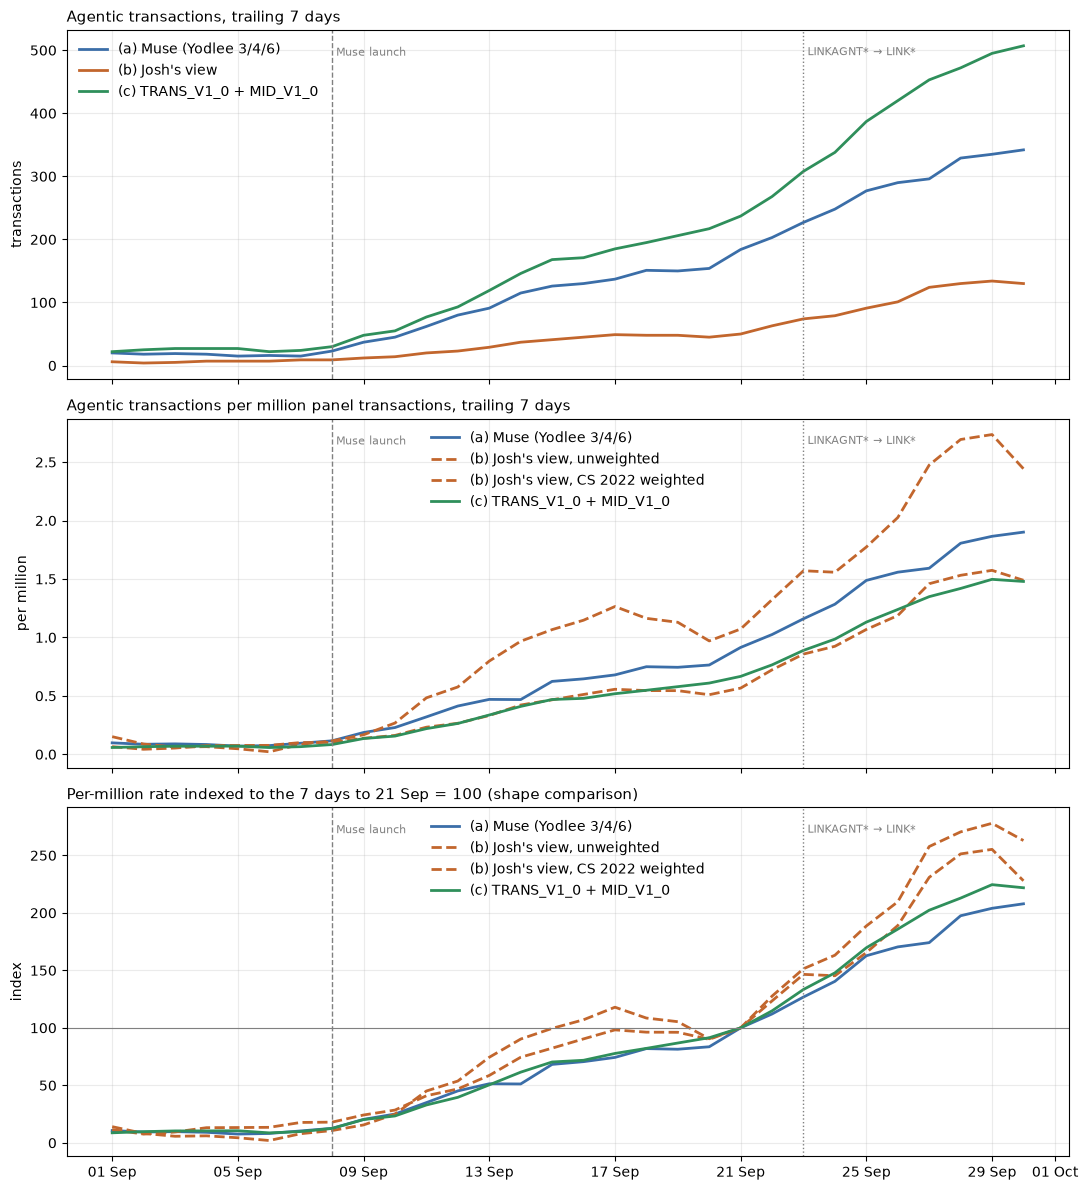

In [7]:
COLORS = {"(a)": "#3b6ea8", "(b)": "#c2662d", "(c)": "#2f8f5b"}
def style(ax, title, ylabel):
    ax.set_title(title, loc="left", fontsize=11)
    ax.set_ylabel(ylabel)
    for x, lbl in [(LAUNCH, "Muse launch"), (RENAME, "LINKAGNT* → LINK*")]:
        ax.axvline(x, color="grey", ls="--" if lbl.startswith("Muse") else ":", lw=1)
        ax.text(x, ax.get_ylim()[1] * 0.95, f" {lbl}", fontsize=8, va="top", color="grey")
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%d %b"))
    ax.grid(alpha=.25)

fig, axes = plt.subplots(3, 1, figsize=(11, 12), sharex=True)
for c in counts:
    axes[0].plot(counts.index, counts[c], label=c, color=COLORS[c[:3]], lw=2)
axes[0].legend(frameon=False)
for c in rates:
    axes[1].plot(rates.index, rates[c], label=c, color=COLORS[c[:3]], lw=2, ls="--" if "weighted" in c else "-")
axes[1].legend(frameon=False)
idx_base = rates.loc["2026-09-21"]
for c in rates:
    axes[2].plot(rates.index, rates[c] / idx_base[c] * 100, label=c, color=COLORS[c[:3]], lw=2,
                 ls="--" if "weighted" in c else "-")
axes[2].axhline(100, color="grey", lw=.8)
axes[2].legend(frameon=False)
style(axes[0], "Agentic transactions, trailing 7 days", "transactions")
style(axes[1], "Agentic transactions per million panel transactions, trailing 7 days", "per million")
style(axes[2], "Per-million rate indexed to the 7 days to 21 Sep = 100 (shape comparison)", "index")
plt.tight_layout()

## 6. What Omega adds beyond Muse

Weekly Omega agentic transactions, split by whether Muse also has them, and by whether they are in Josh's panels.

,"non-panel, not in Muse","non-panel, in Muse","panel, not in Muse","panel, in Muse",total
week,,,,,
2026-08-31,5,8,5,2,20
2026-09-07,26,64,5,24,119
2026-09-14,50,122,13,32,217
2026-09-21,104,225,35,89,453
2026-09-28,65,110,19,38,232


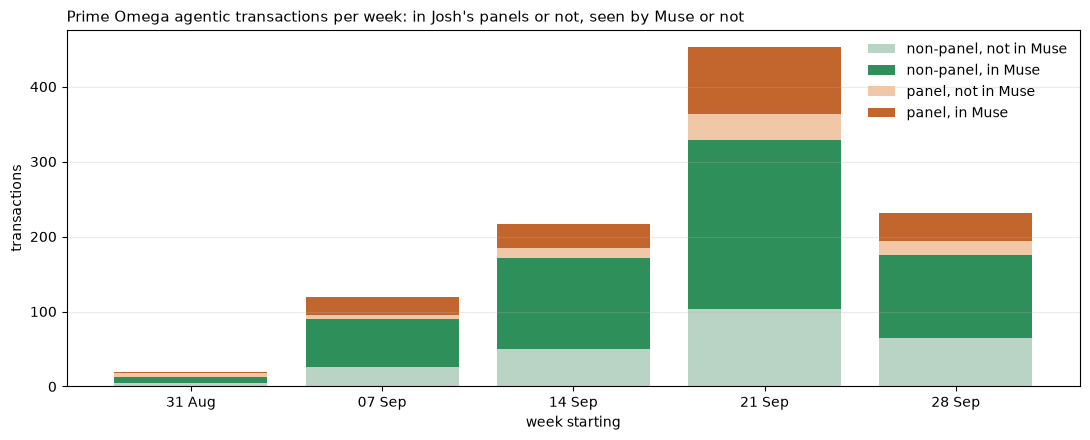

In [8]:
oh = omega_hits[omega_hits.day >= SHOW_FROM]
oh = oh.assign(in_muse=oh.partner_transid.isin(muse_set), week=oh.day.dt.to_period("W-SUN").dt.start_time)
split = oh.pivot_table(index="week", columns=["in_panel", "in_muse"], values="transid", aggfunc="count", fill_value=0)
split.columns = [f"{'panel' if p else 'non-panel'}, {'in Muse' if mu else 'not in Muse'}" for p, mu in split.columns]
ax = split.plot.bar(stacked=True, figsize=(11, 4.5), width=.8,
                    color=["#b9d3c4", "#2f8f5b", "#f0c8a8", "#c2662d"][:split.shape[1]])
ax.set_xticklabels([w.strftime("%d %b") for w in split.index], rotation=0)
ax.set_title("Prime Omega agentic transactions per week: in Josh's panels or not, seen by Muse or not", loc="left", fontsize=11)
ax.set_xlabel("week starting"); ax.set_ylabel("transactions"); ax.grid(axis="y", alpha=.25); ax.legend(frameon=False)
plt.tight_layout()
split.assign(total=split.sum(axis=1))

In [9]:
# Card vs bank mix of Omega agentic transactions, and top descriptors Muse misses
print(oh.groupby(["cardtype", "in_muse"]).size().unstack(fill_value=0))
oh.loc[~oh.in_muse, "merchdesc"].str.upper().str.slice(0, 45).value_counts().head(15)

in_muse   False  True 
cardtype              
bank        261    319
card         66    395


merchdesc
LINK* UNITEL VOICE WWW.LINK.COM CA               4
LINKAGNT* AMERICAN AIR BUFFALO NY USA            4
LINK* SP SUNFOOD SUPER WWW.LINK.CO CA            3
LINK.COM - LINKAGNT*                             3
POS LINKAGNT* DUNKIN SOUTH SAN FRA CA            3
LINKAGNT* PORKBUN.COM WWW.LINK.COM CA            2
LINKAGNT* BLUEBE 5734 SOUTH SAN FRA CA JSDH7K    2
ACH WEB ST-____________ LINK.COM LINKAGNT*       2
LINK* SP KACHAVA WWW.LINK.COM CA                 2
LINK* APPL 354 OYSTER POINT BOULEVSOUTH SAN F    2
LINK* NJ BUSINESS SERV WWW.LINK.CO CA            2
DC : PURCH LINKAGNT* SP PREMIER 5734 WWW.LINK    2
LINKAGNT* MACUNGIES PO WWW.LINK.CO CA            2
LINK* AMSOIL WWW.LINK.COM CA                     2
CC : CREDIT CARD PURCH LINK* CLOUDFLARE 5734     2
Name: count, dtype: int64